# Gatekeeper · 04 — Models 4 and 5: AdaBoost and gradient boosting (LightGBM)

Bagging and random forests train trees **side by side** and average them, which cuts variance.
Boosting trains small trees **one after another**, each focusing on what the previous ones got
wrong, which cuts bias.

- **AdaBoost** re-weights the payments: ones the current model misjudges count more for the next tree.
- **Gradient boosting** fits each new tree to the remaining errors directly. LightGBM is a fast,
  industry-standard implementation.

Same features, splits and scoring as the earlier models.

**Input:** the `train` / `valid` parquet files produced by `01_explore_and_split`.

## 1. Setup — the same in every contest notebook

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEARCH_ROOT = os.environ.get("GK_DATA_ROOT", "/kaggle/input")
OUT_DIR = os.environ.get("GK_OUT_DIR", "/kaggle/working")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name):
    hits = glob.glob(f"{SEARCH_ROOT}/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found: attach the output of 01_explore_and_split as input")
    return hits[0]

train = pd.read_parquet(find("train.parquet"))
valid = pd.read_parquet(find("valid.parquet"))
print(f"train {len(train):,} rows · valid {len(valid):,} rows")

train 414,542 rows · valid 90,568 rows


### Features

- **Not features:** IDs and time counters only record order (`TransactionID`, `TransactionDT`, `day`, `week`).
- **Text columns** (card type, email domain, device…) become numbers: each value gets a code learned from `train`;
  values never seen in training get `-2`.
- **Missing values** become `-999`. Trees simply learn "missing" as its own branch.
  Every model gets this same input, so the comparison is fair.

In [2]:
TARGET = "isFraud"
NOT_FEATURES = {TARGET, "TransactionID", "TransactionDT", "day", "week"}
features = [c for c in train.columns if c not in NOT_FEATURES]
text_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]

codes = {c: {v: i for i, v in enumerate(train[c].dropna().unique())} for c in text_cols}

def prepare(df):
    X = df[features].copy()
    for c in text_cols:
        X[c] = X[c].map(codes[c]).astype("float32").where(df[c].notna(), -1).fillna(-2)
    return X.fillna(-999).astype("float32")

X_train, y_train = prepare(train), train[TARGET].values
X_valid, y_valid = prepare(valid), valid[TARGET].values
amount_valid = valid["TransactionAmt"].values
print(f"{len(features)} features ({len(text_cols)} were text)")

431 features (31 were text)


### How every model is scored

| Score | Plain meaning |
|---|---|
| **PR-AUC** | Main score. How well the model ranks fraud above genuine payments. Fraud is rare, so this is far more honest than accuracy. A random guess scores about 0.035 here. |
| **Recall @ 1% false alarms** | If we only allow 1 in 100 genuine customers to be wrongly flagged, what share of fraud do we catch? |
| **Cost** | Money lost: every missed fraud costs its amount, and every genuine customer we block costs **$10** (support, lost sales, annoyance). That $10 is our assumption, written down so it can be changed. |
| **Train time / time per payment** | How long it takes to learn, and how long it takes to judge one payment (matters for the 50 ms target). |

In [3]:
FALSE_ALARM_COST = 10.0   # assumed cost of wrongly blocking one genuine customer ($)

def score(name, model, X, y, amount, train_seconds, notes=""):
    t0 = time.perf_counter()
    p = model.predict_proba(X)[:, 1]
    batch_ms = (time.perf_counter() - t0) / len(X) * 1000

    one = X.iloc[[0]]
    t0 = time.perf_counter()
    for _ in range(50):
        model.predict_proba(one)
    single_ms = (time.perf_counter() - t0) / 50 * 1000

    fpr, tpr, thr = roc_curve(y, p)
    i = np.searchsorted(fpr, 0.01, side="right") - 1
    threshold = thr[max(i, 0)]
    flagged = p >= threshold
    missed_fraud = amount[(y == 1) & ~flagged].sum()
    false_alarms = int(((y == 0) & flagged).sum())

    r = {
        "model": name,
        "pr_auc": round(average_precision_score(y, p), 4),
        "roc_auc": round(roc_auc_score(y, p), 4),
        "recall_at_1pct_fpr": round(tpr[max(i, 0)], 4),
        "cost_usd": round(missed_fraud + false_alarms * FALSE_ALARM_COST),
        "missed_fraud_usd": round(missed_fraud),
        "false_alarms": false_alarms,
        "train_seconds": round(train_seconds, 1),
        "ms_per_payment_single": round(single_ms, 3),
        "ms_per_payment_batch": round(batch_ms, 5),
        "notes": notes,
    }
    return r

def show(results):
    cols = ["model", "pr_auc", "recall_at_1pct_fpr", "cost_usd", "train_seconds", "ms_per_payment_single", "notes"]
    return pd.DataFrame(results)[cols]

# Baseline: a model that never flags anything
never = int(y_valid.sum())
print(f"'Never flag' baseline: catches 0 of {never:,} frauds, cost = ${amount_valid[y_valid == 1].sum():,.0f} (all fraud missed)")

'Never flag' baseline: catches 0 of 3,069 frauds, cost = $492,574 (all fraud missed)


In [4]:
# Single-payment timing on one core, as a live API would run it
_score_base = score
def score(name, model, X, y, amount, train_seconds, notes=""):
    jobs = getattr(model, "n_jobs", None)
    if jobs is not None:
        model.set_params(n_jobs=1)
    try:
        return _score_base(name, model, X, y, amount, train_seconds, notes)
    finally:
        if jobs is not None:
            model.set_params(n_jobs=jobs)

# Earlier results, for comparison
EARLIER = [
    {"model": "Decision tree (pruned)", "pr_auc": 0.3678, "recall_at_1pct_fpr": 0.3095, "cost_usd": 420500,
     "train_seconds": 29.7, "ms_per_payment_single": 3.61, "notes": "from 02"},
    {"model": "Bagging (50 trees)", "pr_auc": 0.5040, "recall_at_1pct_fpr": 0.4262, "cost_usd": 321614,
     "train_seconds": 404.4, "ms_per_payment_single": 7.843, "notes": "from 03"},
    {"model": "Random forest (300 trees)", "pr_auc": 0.5043, "recall_at_1pct_fpr": 0.4164, "cost_usd": 322172,
     "train_seconds": 267.1, "ms_per_payment_single": 16.978, "notes": "from 03"},
]
results = []
print(f"CPU cores available: {os.cpu_count()}")

CPU cores available: 4


## 1. AdaBoost

AdaBoost builds trees strictly one at a time, so it cannot use several cores and is the slowest
model here. The size of each small tree is chosen on a 120,000-row sample; the final model is
trained on all training rows.

In [5]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(42)
idx = rng.choice(len(X_train), min(120_000, len(X_train)), replace=False)
X_tune, y_tune = X_train.iloc[idx], y_train[idx]

for depth in [1, 2, 3]:
    t0 = time.perf_counter()
    m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth), n_estimators=50,
                           learning_rate=0.5, random_state=42).fit(X_tune, y_tune)
    v = average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])
    print(f"depth {depth} trees, 50 rounds, sample: valid PR-AUC {v:.3f}  ({time.perf_counter() - t0:.0f}s)")
    if depth == 1 or v > best_v:
        best_depth, best_v = depth, v
print(f"\nBest tree size: depth {best_depth}")

depth 1 trees, 50 rounds, sample: valid PR-AUC 0.334  (40s)
depth 2 trees, 50 rounds, sample: valid PR-AUC 0.370  (75s)
depth 3 trees, 50 rounds, sample: valid PR-AUC 0.409  (109s)

Best tree size: depth 3


In [6]:
t0 = time.perf_counter()
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=best_depth), n_estimators=100,
                         learning_rate=0.5, random_state=42).fit(X_train, y_train)
ada_secs = time.perf_counter() - t0
print(f"100 rounds on all {len(X_train):,} rows in {ada_secs:.0f}s")

# Score after each round, to see how boosting improves step by step
rounds, ada_curve = [], []
for i, p in enumerate(ada.staged_predict_proba(X_valid), start=1):
    if i in (1, 5, 10, 25, 50, 75, 100):
        rounds.append(i); ada_curve.append(average_precision_score(y_valid, p[:, 1]))
for r, v in zip(rounds, ada_curve):
    print(f"{r:>3} rounds: {v:.3f}")

results.append(score("AdaBoost (100 rounds)", ada, X_valid, y_valid, amount_valid, ada_secs,
                     f"depth-{best_depth} trees, learning_rate 0.5"))

100 rounds on all 414,542 rows in 893s
  1 rounds: 0.161
  5 rounds: 0.301
 10 rounds: 0.337
 25 rounds: 0.377
 50 rounds: 0.391
 75 rounds: 0.396
100 rounds: 0.401


## 2. Gradient boosting with LightGBM

- Many small trees (up to 127 leaves each), each fitted to the errors left by the trees before it.
- `learning_rate` shrinks each tree's contribution, so the model improves in small, safe steps.
- **Early stopping:** training halts once the `valid` score stops improving for 100 rounds.

Early stopping uses `valid` to decide when to stop, so `valid` is slightly favourable to this model.
The untouched `replay` split remains the final, fully fair test for the champion.

[200]	valid_0's average_precision: 0.596644	valid_0's binary_logloss: 0.0816664
[400]	valid_0's average_precision: 0.615544	valid_0's binary_logloss: 0.0802539
Stopped at 472 trees in 170s


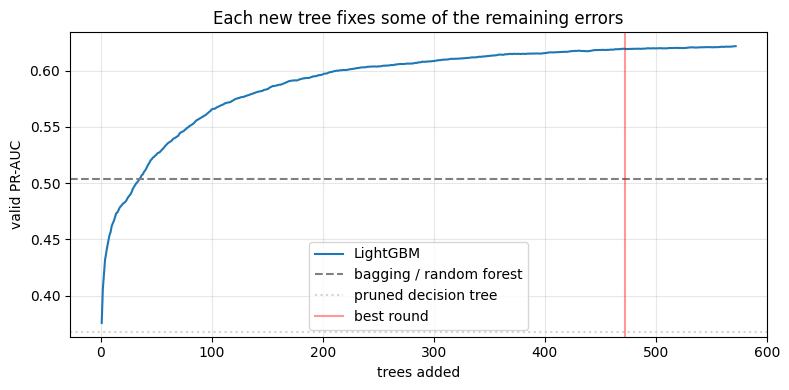

In [7]:
import warnings
import lightgbm as lgb
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated.*")

lgbm = lgb.LGBMClassifier(
    n_estimators=5000, learning_rate=0.05, num_leaves=127, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
    n_jobs=-1, random_state=42, verbose=-1,
)
t0 = time.perf_counter()
lgbm.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], eval_metric="average_precision",
         callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)])
lgbm_secs = time.perf_counter() - t0
print(f"Stopped at {lgbm.best_iteration_} trees in {lgbm_secs:.0f}s")

curve = lgbm.evals_result_["valid_0"]["average_precision"]
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(curve) + 1), curve, label="LightGBM")
plt.axhline(0.504, color="gray", ls="--", label="bagging / random forest")
plt.axhline(0.368, color="lightgray", ls=":", label="pruned decision tree")
plt.axvline(lgbm.best_iteration_, color="red", alpha=0.4, label="best round")
plt.xlabel("trees added"); plt.ylabel("valid PR-AUC"); plt.title("Each new tree fixes some of the remaining errors")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

results.append(score("LightGBM", lgbm, X_valid, y_valid, amount_valid, lgbm_secs,
                     f"{lgbm.best_iteration_} trees, lr 0.05, 127 leaves, early stopping"))

## 3. The full contest so far

In [8]:
table = show(EARLIER + results).sort_values("pr_auc", ascending=False).reset_index(drop=True)
table

,model,pr_auc,recall_at_1pct_fpr,cost_usd,train_seconds,ms_per_payment_single,notes
0,LightGBM,0.6195,0.5279,256208,169.9,2.442,"472 trees, lr 0.05, 127 leaves, early stopping"
1,Random forest (300 trees),0.5043,0.4164,322172,267.1,16.978,from 03
2,Bagging (50 trees),0.5040,0.4262,321614,404.4,7.843,from 03
3,AdaBoost (100 rounds),0.4009,0.3265,391691,893.4,22.767,"depth-3 trees, learning_rate 0.5"
4,Decision tree (pruned),0.3678,0.3095,420500,29.7,3.610,from 02


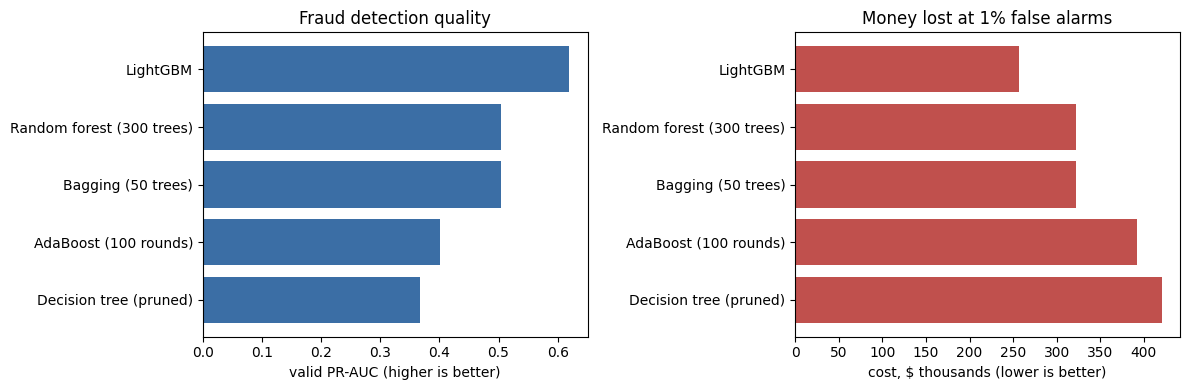

In [9]:
board = pd.DataFrame(EARLIER + results).sort_values("pr_auc")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(board["model"], board["pr_auc"], color="#3b6ea5")
axes[0].set_xlabel("valid PR-AUC (higher is better)"); axes[0].set_title("Fraud detection quality")
axes[1].barh(board["model"], board["cost_usd"] / 1000, color="#c0504d")
axes[1].set_xlabel("cost, $ thousands (lower is better)"); axes[1].set_title("Money lost at 1% false alarms")
plt.tight_layout(); plt.show()

## 4. What LightGBM relies on

Importance here is **gain**: how much each column improved the model in total across all its splits.

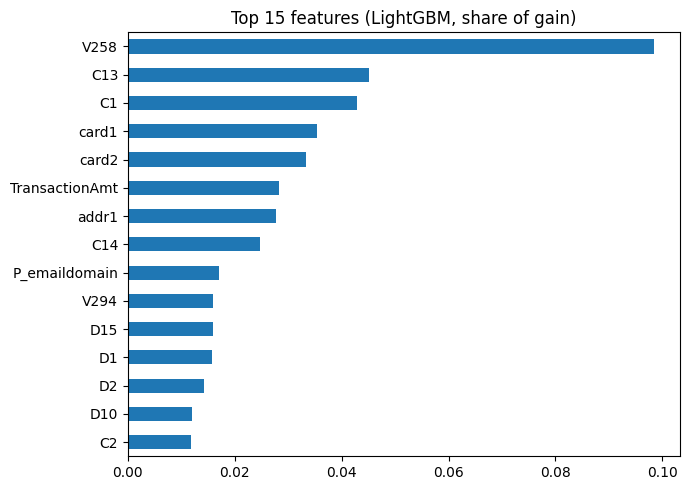

Top 6: V258, C13, C1, card1, card2, TransactionAmt


In [10]:
gain = pd.Series(lgbm.booster_.feature_importance("gain"), index=features)
top = (gain / gain.sum()).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
top[::-1].plot.barh(ax=ax, title="Top 15 features (LightGBM, share of gain)")
plt.tight_layout(); plt.show()
print("Top 6:", ", ".join(top.index[:6]))

## 5. Save results and the model files

The trained LightGBM model and the exact input preparation (feature order, text codes) are saved
so the scoring API can reproduce the same inputs for live payments.

In [11]:
with open(f"{OUT_DIR}/results_boosting.json", "w") as f:
    json.dump(results, f, indent=2)

lgbm.booster_.save_model(f"{OUT_DIR}/lightgbm_model.txt", num_iteration=lgbm.best_iteration_)
with open(f"{OUT_DIR}/preprocess.json", "w") as f:
    json.dump({"features": features, "text_cols": text_cols,
               "codes": {c: {str(k): v for k, v in m.items()} for c, m in codes.items()},
               "missing_value": -999, "unseen_text": -2, "missing_text": -1}, f)

for name in ["results_boosting.json", "lightgbm_model.txt", "preprocess.json"]:
    print(f"saved {name:<22} {os.path.getsize(f'{OUT_DIR}/{name}') / 1e6:.1f} MB")

saved results_boosting.json  0.0 MB
saved lightgbm_model.txt     6.6 MB
saved preprocess.json        0.1 MB
